In [13]:
import os
if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 2 # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    print(f"Using GPU {gpu_num}")
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')

import pandas as pd
from data_preprocessing import preprocess_data_channel, preprocess_data
from evaluation import print_metrics_multiclass, print_metrics
from visualization import plot_confusion_matrix_multiclass, plot_roc_curve_multiclass, plot_confusion_matrix, plot_roc_curve
from ml_algorithms import train_knn, train_svm, train_random_forest, train_xgboost


Full Dataset NLOS/LOS Classification
====================================

In [2]:
# Load the datasets
df_tdl_cdl = pd.read_csv("dataset_tdl_cdl_training.csv")
df_tdl_cdl_test = pd.read_csv("dataset_tdl_cdl_testing.csv")
# Make the dataset for tdl only and cdl only (based on the column name model_type)
df_tdl = df_tdl_cdl[df_tdl_cdl['model_type'] == 'tdl']
df_cdl = df_tdl_cdl[df_tdl_cdl['model_type'] == 'cdl']
df_tdl_test = df_tdl_cdl_test[df_tdl_cdl_test['model_type'] == 'tdl']
df_cdl_test = df_tdl_cdl_test[df_tdl_cdl_test['model_type'] == 'cdl']

# df_sionna_mimo_los = pd.read_csv("dataset_sionna_mimo_los.csv")
# df_sionna_mimo_los_test = pd.read_csv("dataset_sionna_mimo_los_test.csv")
# df_sionna_mimo_nlos = pd.read_csv("dataset_sionna_mimo_nlos.csv")
# df_sionna_mimo_nlos_test = pd.read_csv("dataset_sionna_mimo_nlos_test.csv")

# # concatenate the datasets
# df_sionna_mimo = pd.concat([df_sionna_mimo_los, df_sionna_mimo_nlos])
# df_sionna_mimo_test = pd.concat([df_sionna_mimo_los_test, df_sionna_mimo_nlos_test])


In [3]:
# Concatenate full  the datasets in training and testing
# df_full = pd.concat([df_tdl_cdl, df_sionna_mimo])
# df_full_test = pd.concat([df_tdl_cdl_test, df_sionna_mimo_test])
df_full = df_tdl_cdl
df_full_test = df_tdl_cdl_test
# Preprocess the data
features, labels = preprocess_data_channel(df_full)
features_test, labels_test = preprocess_data_channel(df_full_test)
# Train the model and get predictions


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:50: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Dat

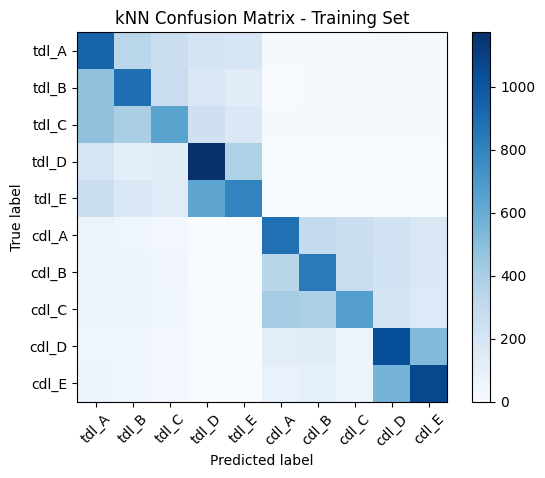

Confusion Matrix:
[[ 936  337  260  210  186   10   10   17   19   15]
 [ 482  892  270  165  130    9   12   12   14   14]
 [ 479  395  646  247  173   10   11   14   13   12]
 [ 195  119  132 1173  377    1    1    2    0    0]
 [ 260  165  141  629  793    2    3    4    0    3]
 [  63   52   36    2    4  880  302  258  227  176]
 [  60   64   38    0    2  342  834  274  221  165]
 [  65   63   42    7    4  408  382  665  204  160]
 [  54   45   32    0    1  122  132   63 1031  520]
 [  55   43   34    0    1   80  106   60  556 1065]]


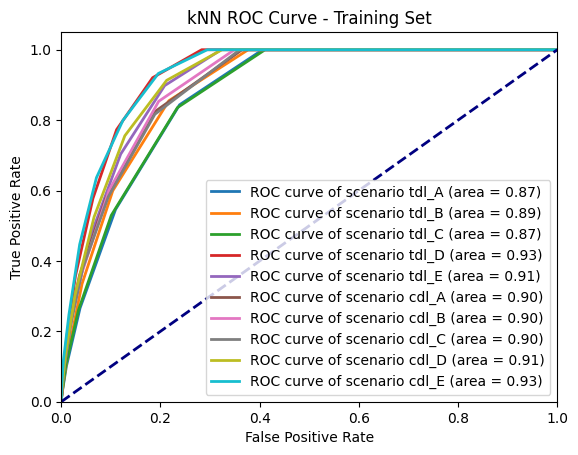

Metrics for Training Set:
Accuracy: 0.4457
Precision: 0.4490
Recall: 0.4458
F1 Score: 0.4434
ROC AUC: 0.9011
Log Loss: 1.2377


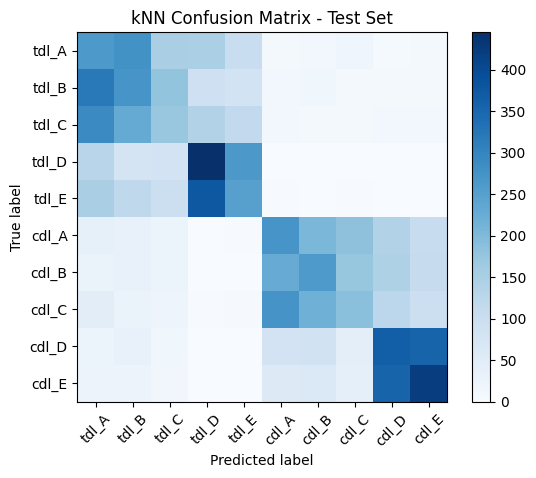

Confusion Matrix:
[[264 278 150 148 104  10  13  20   6   7]
 [319 270 179  93  82  13  17   9   9   9]
 [290 231 171 140 115  12   9   7  13  12]
 [129  79  80 445 265   0   0   1   0   1]
 [150 121  97 376 249   3   1   2   1   0]
 [ 38  34  23   0   2 271 204 183 138 107]
 [ 29  33  23   0   0 227 262 174 143 109]
 [ 46  29  21   2   5 272 218 186 124  97]
 [ 23  32  17   0   1  81  84  43 364 355]
 [ 25  26  15   0   1  57  62  39 356 419]]


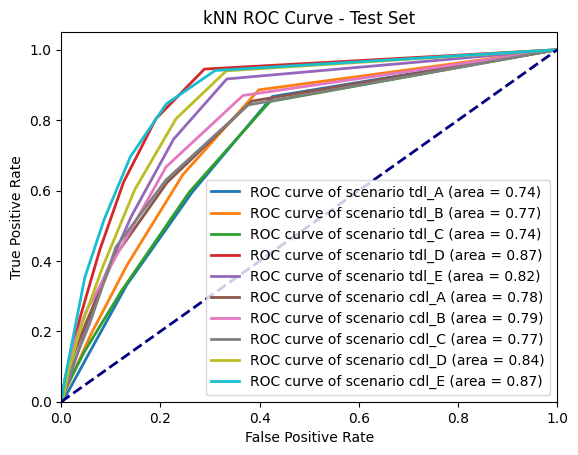

Metrics for Test Set:
Accuracy: 0.2901
Precision: 0.2890
Recall: 0.2901
F1 Score: 0.2867
ROC AUC: 0.7993
Log Loss: 5.1548


In [4]:

class_labels = df_full["model_type"] + "_" + df_full["scenario"].astype(str)
class_labels = class_labels.unique()

# SVM
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_knn(features, labels, features_test, labels_test, n_neighbors=10)
# Plot confusion matrix and ROC curve for training semulticlass(y_train, y_train_pred, title='Confusion Matrix - Training Set')
plot_confusion_matrix_multiclass(y_train, y_train_pred, class_labels, title='kNN Confusion Matrix - Training Set')
plot_roc_curve_multiclass(y_train, y_train_prob, class_labels,title='kNN ROC Curve - Training Set')

# Print metrics for training set
print("Metrics for Training Set:")
print_metrics_multiclass(y_train, y_train_pred, y_train_prob)


# Plot confusion matrix and ROC curve for test set

class_labels = df_full_test["model_type"] + "_" + df_full_test["scenario"].astype(str)
class_labels = class_labels.unique()
plot_confusion_matrix_multiclass(y_test, y_test_pred, class_labels, title='kNN Confusion Matrix - Test Set')
plot_roc_curve_multiclass(y_test, y_test_prob, class_labels, title='kNN ROC Curve - Test Set')

# Print metrics for test set
print("Metrics for Test Set:")
print_metrics_multiclass(y_test, y_test_pred, y_test_prob)


In [5]:
# SVM
class_labels_train = df_full["model_type"] + "_" + df_full["scenario"].astype(str)
class_labels_train = class_labels_train.unique()

class_labels_test = df_full_test["model_type"] + "_" + df_full_test["scenario"].astype(str)
class_labels_test = class_labels_test.unique()
print("Training with SVM...")
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_svm(
    features, labels, features_test, labels_test, kernel='rbf', C=1.0
)


Training with SVM...


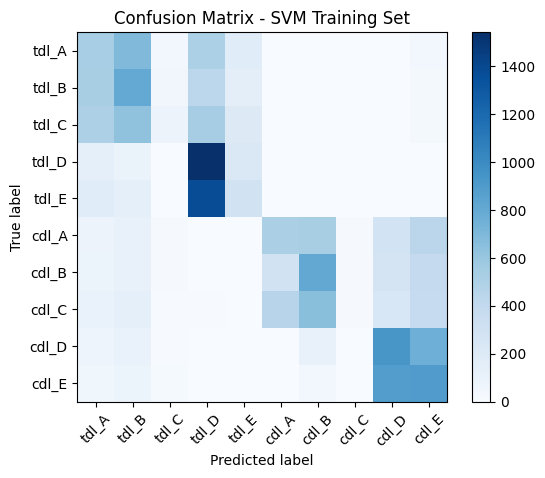

Confusion Matrix:
[[ 534  691   41  507  179    0    5    1    3   39]
 [ 527  806   53  432  145    0    4    0    1   32]
 [ 505  632   87  537  195    0    2    2    6   34]
 [ 137   98    0 1541  223    0    0    1    0    0]
 [ 180  138    2 1369  298    1    5    1    0    6]
 [  89  114   17    2    2  514  527   15  285  435]
 [  95  113   13    0    1  297  810   13  271  387]
 [ 103  134    8    8    2  457  654   15  236  383]
 [  76  108   11    0    0    0  111    1  931  762]
 [  55   94   23    0    0    0   47    4  884  893]]


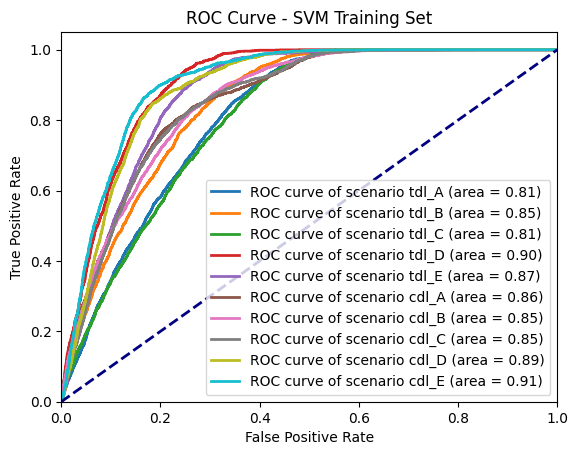

Metrics for SVM Training Set:
Accuracy: 0.3215
Precision: 0.3203
Recall: 0.3215
F1 Score: 0.2811
ROC AUC: 0.8604
Log Loss: 1.4958


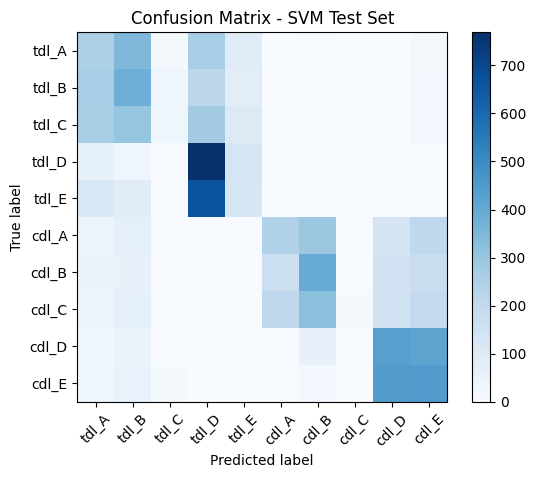

Confusion Matrix:
[[254 346  18 267  92   0   5   1   0  17]
 [265 380  31 217  80   1   2   0   0  24]
 [263 304  31 278  99   1   2   1   0  21]
 [ 66  35   1 769 129   0   0   0   0   0]
 [118  86   4 664 125   1   0   0   0   2]
 [ 47  67   5   1   0 244 294   4 133 205]
 [ 50  59   6   0   0 168 392   3 145 177]
 [ 42  68   6   3   2 206 322  10 147 194]
 [ 35  51   6   0   0   0  56   3 432 417]
 [ 30  53  11   0   0   0  22   2 439 443]]


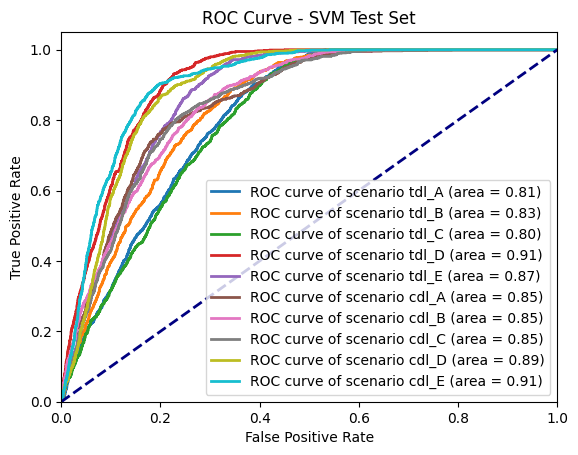

Metrics for SVM Test Set:
Accuracy: 0.3080
Precision: 0.3123
Recall: 0.3080
F1 Score: 0.2670
ROC AUC: 0.8566
Log Loss: 1.5070


In [6]:

plot_confusion_matrix_multiclass(y_train, y_train_pred, class_labels_train, title='Confusion Matrix - SVM Training Set')
plot_roc_curve_multiclass(y_train, y_train_prob, class_labels_train, title='ROC Curve - SVM Training Set')
print("Metrics for SVM Training Set:")
print_metrics_multiclass(y_train, y_train_pred, y_train_prob)

plot_confusion_matrix_multiclass(y_test, y_test_pred, class_labels_test, title='Confusion Matrix - SVM Test Set')
plot_roc_curve_multiclass(y_test, y_test_prob, class_labels_test, title='ROC Curve - SVM Test Set')
print("Metrics for SVM Test Set:")
print_metrics_multiclass(y_test, y_test_pred, y_test_prob)



Training with Random Forest...


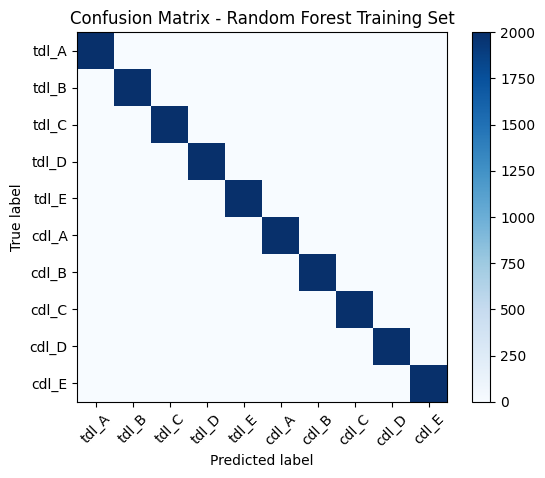

Confusion Matrix:
[[2000    0    0    0    0    0    0    0    0    0]
 [   0 2000    0    0    0    0    0    0    0    0]
 [   0    0 2000    0    0    0    0    0    0    0]
 [   0    0    0 2000    0    0    0    0    0    0]
 [   0    0    0    0 2000    0    0    0    0    0]
 [   0    0    0    0    0 2000    0    0    0    0]
 [   0    0    0    0    0    0 2000    0    0    0]
 [   0    0    0    0    0    0    0 2000    0    0]
 [   0    0    0    0    0    0    0    0 2000    0]
 [   0    0    0    0    0    0    0    0    0 2000]]


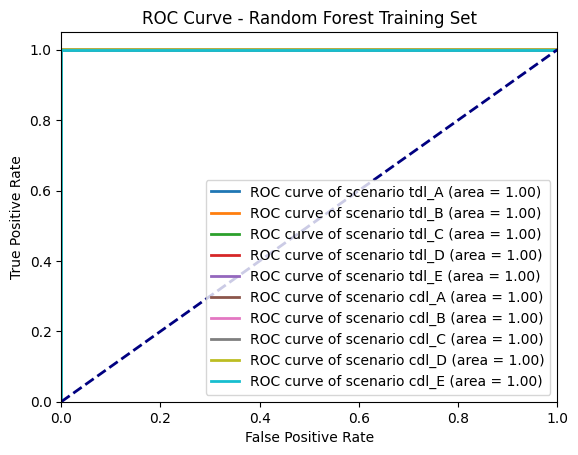

Metrics for Random Forest Training Set:
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
ROC AUC: 1.0000
Log Loss: 0.3016


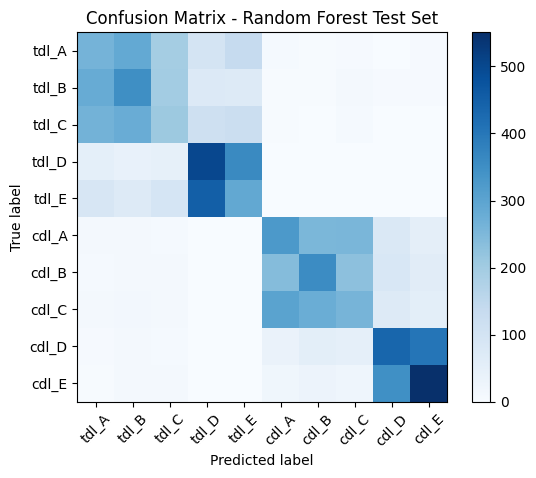

Confusion Matrix:
[[261 287 194  97 136   8   3   6   2   6]
 [281 350 196  74  73   3   4   9   5   5]
 [263 278 207 112 124   4   2   8   2   0]
 [ 50  39  47 501 360   2   0   1   0   0]
 [ 89  71  94 450 290   2   0   1   2   1]
 [ 12  12   8   0   0 327 253 255  80  53]
 [  8   9  10   0   0 240 357 230  85  61]
 [  9  14  10   0   2 303 276 259  72  55]
 [  6   9   8   0   0  35  54  49 435 404]
 [  4  10  11   0   0  21  31  25 347 551]]


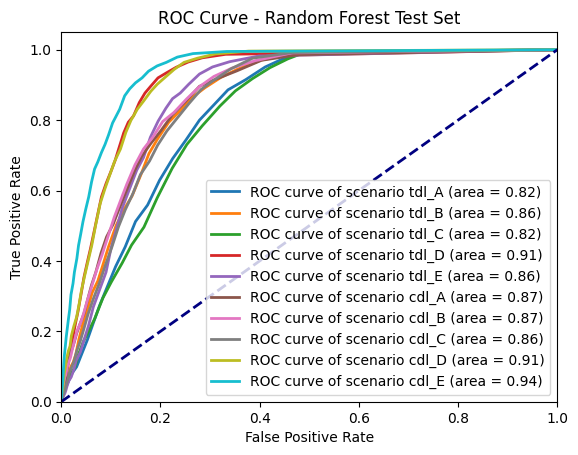

Metrics for Random Forest Test Set:
Accuracy: 0.3538
Precision: 0.3479
Recall: 0.3538
F1 Score: 0.3495
ROC AUC: 0.8715
Log Loss: 1.7436


In [7]:

# Random Forest
print("\nTraining with Random Forest...")
from sklearn.ensemble import RandomForestClassifier
def train_random_forest(features, labels, features_test, labels_test, n_estimators=50, max_depth=None, min_samples_split=2, min_samples_leaf=1, max_features='sqrt'):
    # Initialize the Random Forest classifier with regularization
    rf = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,  # Limit the depth of the trees
        min_samples_split=min_samples_split,  # Minimum samples required to split a node
        min_samples_leaf=min_samples_leaf,  # Minimum samples required in a leaf
        max_features=max_features,  # Number of features to consider at each split
        random_state=42
    )
    
    # Train the model
    rf.fit(features, labels)
    
    # Get predictions
    y_train_pred = rf.predict(features)
    y_train_prob = rf.predict_proba(features) if hasattr(rf, "predict_proba") else None
    
    y_test_pred = rf.predict(features_test)
    y_test_prob = rf.predict_proba(features_test) if hasattr(rf, "predict_proba") else None
    
    return labels, y_train_pred, y_train_prob, labels_test, y_test_pred, y_test_prob
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_random_forest(features, labels, features_test, labels_test)
plot_confusion_matrix_multiclass(y_train, y_train_pred, class_labels_train, title='Confusion Matrix - Random Forest Training Set')
plot_roc_curve_multiclass(y_train, y_train_prob, class_labels_train, title='ROC Curve - Random Forest Training Set')
print("Metrics for Random Forest Training Set:")
print_metrics_multiclass(y_train, y_train_pred, y_train_prob)

plot_confusion_matrix_multiclass(y_test, y_test_pred, class_labels_test, title='Confusion Matrix - Random Forest Test Set')
plot_roc_curve_multiclass(y_test, y_test_prob, class_labels_test, title='ROC Curve - Random Forest Test Set')
print("Metrics for Random Forest Test Set:")
print_metrics_multiclass(y_test, y_test_pred, y_test_prob)



Training with Random Forest...
Performing cross-validation...
Cross-Validation Accuracy: 0.3663 ± 0.0066


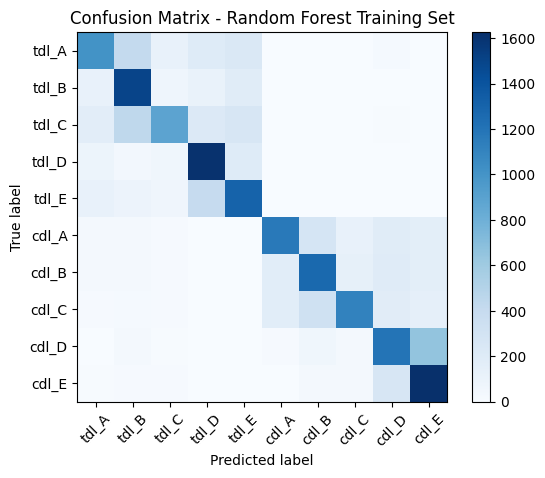

Confusion Matrix:
[[1009  413  119  202  229    2    0    3   21    2]
 [ 123 1495   75  109  189    0    0    4    5    0]
 [ 168  443  884  222  265    2    0    4   10    2]
 [  87   40   60 1613  197    0    1    2    0    0]
 [ 124   92   68  405 1307    0    0    4    0    0]
 [  29   38   16    0    1 1163  279  124  185  165]
 [  33   27   16    0    0  172 1264  138  191  159]
 [  19   24   19    0    1  176  327 1110  183  141]
 [   5   28    9    0    0   16   63   32 1197  650]
 [  11   19   19    0    0    3   29   37  256 1626]]


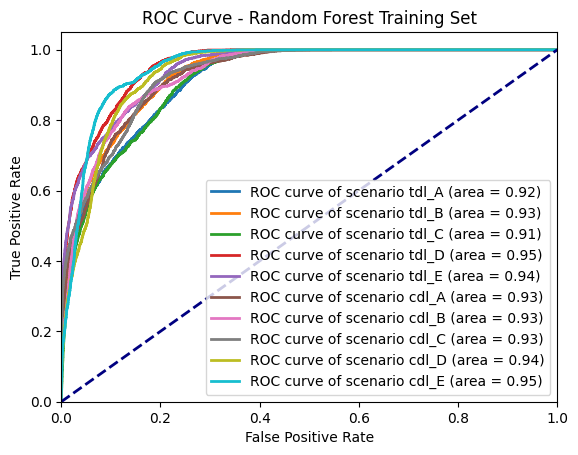

Metrics for Random Forest Training Set:
Accuracy: 0.6334
Precision: 0.6456
Recall: 0.6334
F1 Score: 0.6293
ROC AUC: 0.9334
Log Loss: 1.1967


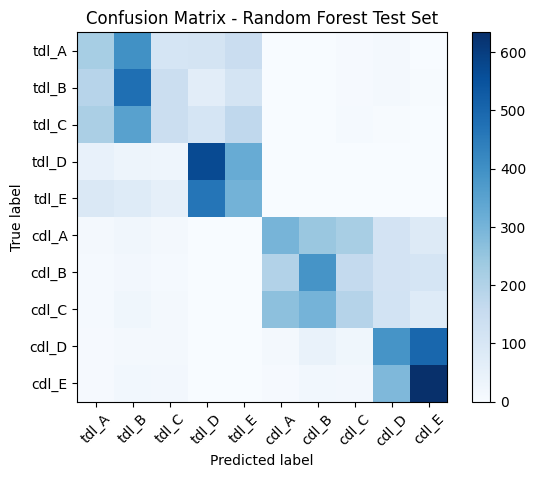

Confusion Matrix:
[[219 398 108 113 145   0   0   7  10   0]
 [187 479 140  65 109   0   0   6  11   3]
 [212 354 143 108 169   1   0   8   4   1]
 [ 45  31  29 569 323   1   0   2   0   0]
 [ 94  79  55 465 304   0   0   1   2   0]
 [ 11  22  12   0   0 299 243 216 116  81]
 [  9  17   8   0   0 196 387 161 115 107]
 [  9  24  14   0   1 264 300 191 118  79]
 [  5  14  13   0   0  14  44  24 387 499]
 [  5  19  16   0   0   7  18  15 286 634]]


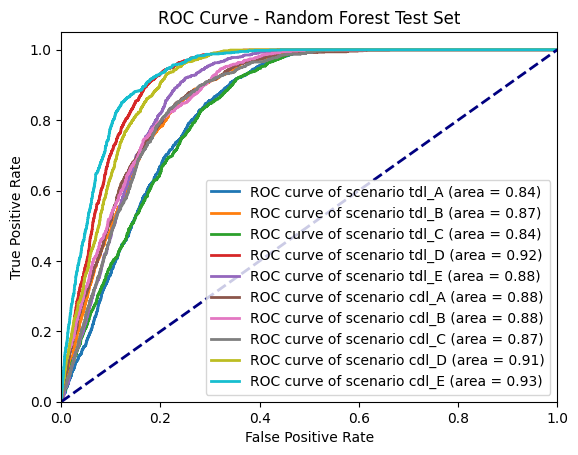

Metrics for Random Forest Test Set:
Accuracy: 0.3612
Precision: 0.3490
Recall: 0.3612
F1 Score: 0.3473
ROC AUC: 0.8807
Log Loss: 1.3899


In [8]:
# Random Forest
print("\nTraining with Random Forest...")
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

def train_random_forest(features, labels, features_test, labels_test, n_estimators=50, max_depth=10, min_samples_split=5, min_samples_leaf=2, max_features='sqrt'):
    # Initialize the Random Forest classifier with regularization
    rf = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,  # Limit the depth of the trees
        min_samples_split=min_samples_split,  # Minimum samples required to split a node
        min_samples_leaf=min_samples_leaf,  # Minimum samples required in a leaf
        max_features=max_features,  # Number of features to consider at each split
        random_state=42,
        class_weight='balanced'  # Handle class imbalance
    )
    
    # Perform cross-validation to evaluate the model
    print("Performing cross-validation...")
    cv_scores = cross_val_score(rf, features, labels, cv=5, scoring='accuracy')
    print(f"Cross-Validation Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    
    # Train the model
    rf.fit(features, labels)
    
    # Get predictions
    y_train_pred = rf.predict(features)
    y_train_prob = rf.predict_proba(features) if hasattr(rf, "predict_proba") else None
    
    y_test_pred = rf.predict(features_test)
    y_test_prob = rf.predict_proba(features_test) if hasattr(rf, "predict_proba") else None
    
    return labels, y_train_pred, y_train_prob, labels_test, y_test_pred, y_test_prob

# Updated hyperparameters for better generalization
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_random_forest(
    features, labels, features_test, labels_test, 
    n_estimators=100, max_depth=10, min_samples_split=5, min_samples_leaf=2, max_features='sqrt'
)

# Plot confusion matrix and ROC curve for training set
plot_confusion_matrix_multiclass(y_train, y_train_pred, class_labels_train, title='Confusion Matrix - Random Forest Training Set')
plot_roc_curve_multiclass(y_train, y_train_prob, class_labels_train, title='ROC Curve - Random Forest Training Set')
print("Metrics for Random Forest Training Set:")
print_metrics_multiclass(y_train, y_train_pred, y_train_prob)

# Plot confusion matrix and ROC curve for test set
plot_confusion_matrix_multiclass(y_test, y_test_pred, class_labels_test, title='Confusion Matrix - Random Forest Test Set')
plot_roc_curve_multiclass(y_test, y_test_prob, class_labels_test, title='ROC Curve - Random Forest Test Set')
print("Metrics for Random Forest Test Set:")
print_metrics_multiclass(y_test, y_test_pred, y_test_prob)


Training with XGBoost...


/home/l2nguyen/miniconda3/envs/mlp/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [11:10:25] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_gpu", "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


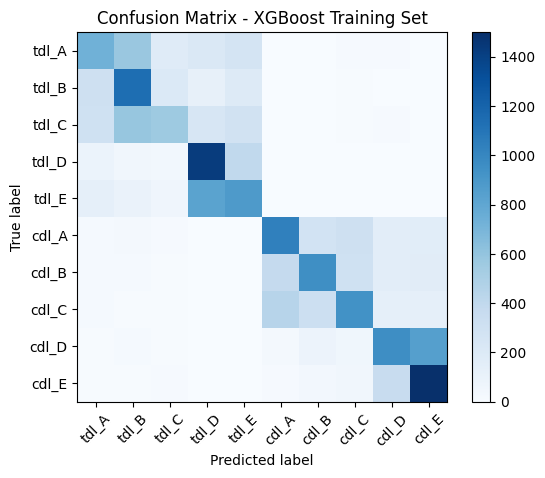

Confusion Matrix:
[[ 730  579  180  219  259    3    1   13   12    4]
 [ 316 1140  208  121  192    3    1   10    5    4]
 [ 304  588  557  240  284    4    2    6   12    3]
 [  88   47   43 1427  394    1    0    0    0    0]
 [ 130   99   59  824  883    2    1    2    0    0]
 [  19   25   13    0    1 1032  280  313  156  161]
 [  23   18    9    0    0  377  951  300  156  166]
 [  19    7    8    1    1  440  324  937  132  131]
 [   6   20    8    0    0   24   83   53  959  847]
 [   9   11   14    0    0   15   41   51  359 1500]]


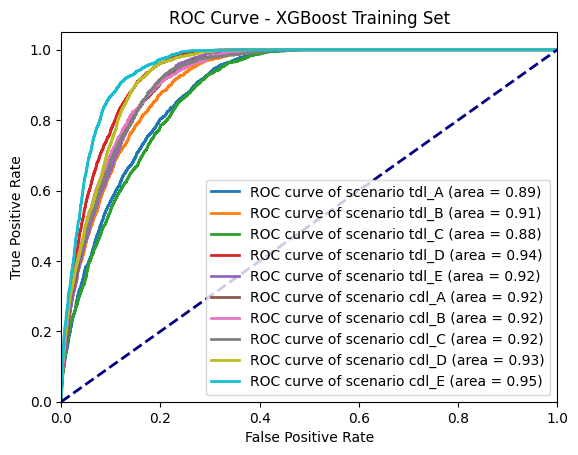

Metrics for XGBoost Training Set:
Accuracy: 0.5058
Precision: 0.5075
Recall: 0.5058
F1 Score: 0.4976
ROC AUC: 0.9191
Log Loss: 1.2220


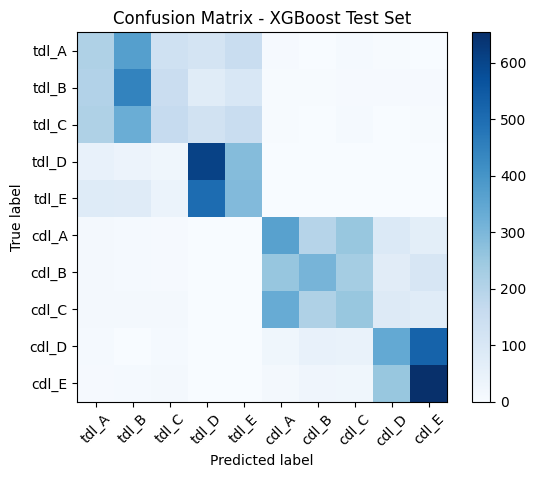

Confusion Matrix:
[[212 370 132 113 151   6   1   9   4   2]
 [204 444 150  76 100   3   4   7   6   6]
 [212 329 161 127 152   3   1  10   1   4]
 [ 46  36  24 608 284   0   0   2   0   0]
 [ 80  78  40 503 291   2   2   1   2   1]
 [ 14   9   7   0   0 364 196 255  90  65]
 [ 14   8   6   0   0 256 308 232  73 103]
 [ 14  12  11   0   2 334 212 254  85  76]
 [  8   1   8   0   0  25  47  45 340 526]
 [  7   9  11   0   0  14  26  25 254 654]]


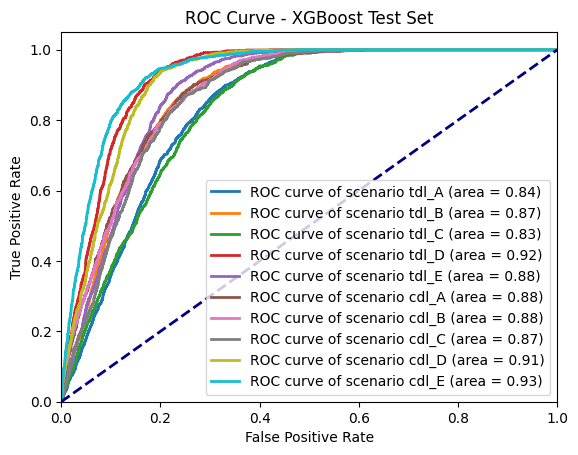

Metrics for XGBoost Test Set:
Accuracy: 0.3636
Precision: 0.3523
Recall: 0.3636
F1 Score: 0.3509
ROC AUC: 0.8812
Log Loss: 1.3784


In [11]:
# XGBoost
print("\nTraining with XGBoost...")
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_xgboost(
    features, labels, features_test, labels_test, n_estimators=100, learning_rate=0.1, max_depth=5
)
plot_confusion_matrix_multiclass(y_train, y_train_pred, class_labels_train, title='Confusion Matrix - XGBoost Training Set')
plot_roc_curve_multiclass(y_train, y_train_prob, class_labels_train, title='ROC Curve - XGBoost Training Set')
print("Metrics for XGBoost Training Set:")
print_metrics_multiclass(y_train, y_train_pred, y_train_prob)

plot_confusion_matrix_multiclass(y_test, y_test_pred, class_labels_test, title='Confusion Matrix - XGBoost Test Set')
plot_roc_curve_multiclass(y_test, y_test_prob, class_labels_test, title='ROC Curve - XGBoost Test Set')
print("Metrics for XGBoost Test Set:")
print_metrics_multiclass(y_test, y_test_pred, y_test_prob)

In [14]:
features, labels = preprocess_data(df_tdl_cdl)
features_test, labels_test = preprocess_data(df_tdl_cdl_test)

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b


Training with kNN...


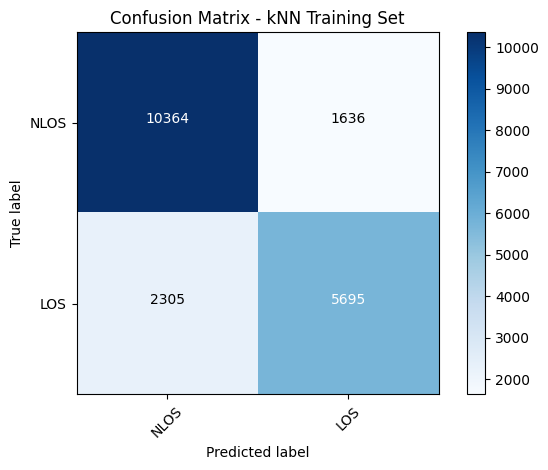

Confusion Matrix:
[[10364  1636]
 [ 2305  5695]]


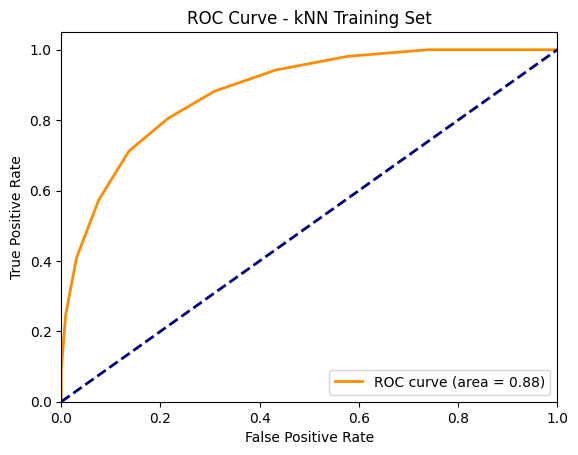

Metrics for kNN Training Set:
Accuracy: 0.8030
Precision: 0.7768
Recall (Sensitivity): 0.7119
Specificity: 0.8637
F1 Score: 0.7429
ROC AUC: 0.8818
Log Loss: 0.4150


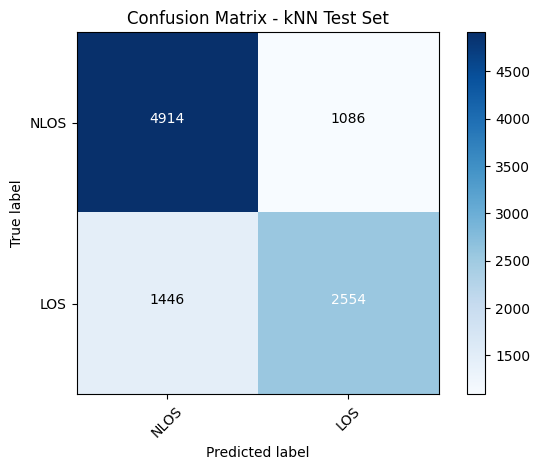

Confusion Matrix:
[[4914 1086]
 [1446 2554]]


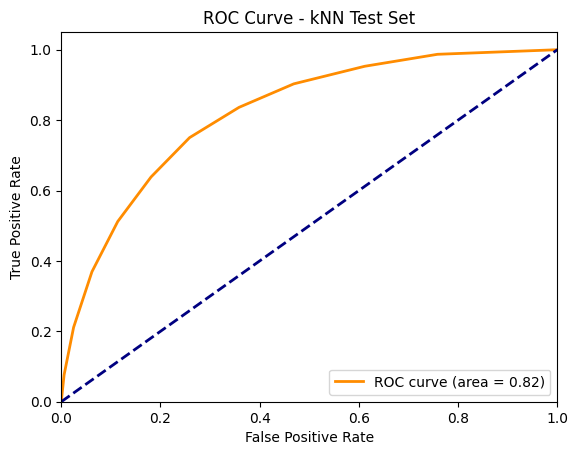

Metrics for kNN Test Set:
Accuracy: 0.7468
Precision: 0.7016
Recall (Sensitivity): 0.6385
Specificity: 0.8190
F1 Score: 0.6686
ROC AUC: 0.8193
Log Loss: 0.7857


In [24]:
print("\nTraining with kNN...")
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_knn(
    features, labels, features_test, labels_test, n_neighbors=10
)
plot_confusion_matrix(y_train, y_train_pred, title='Confusion Matrix - kNN Training Set')

y_train_prob = y_train_prob[:, 1]  # Assuming binary classification, take the probability of the positive class
plot_roc_curve(y_train, y_train_prob, title='ROC Curve - kNN Training Set')
print("Metrics for kNN Training Set:")
print_metrics(y_train, y_train_pred, y_train_prob)

plot_confusion_matrix(y_test, y_test_pred, title='Confusion Matrix - kNN Test Set')
y_test_prob = y_test_prob[:, 1]  # Assuming binary classification, take the probability of the positive class
plot_roc_curve(y_test, y_test_prob, title='ROC Curve - kNN Test Set')
print("Metrics for kNN Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob)


Training with SVM...


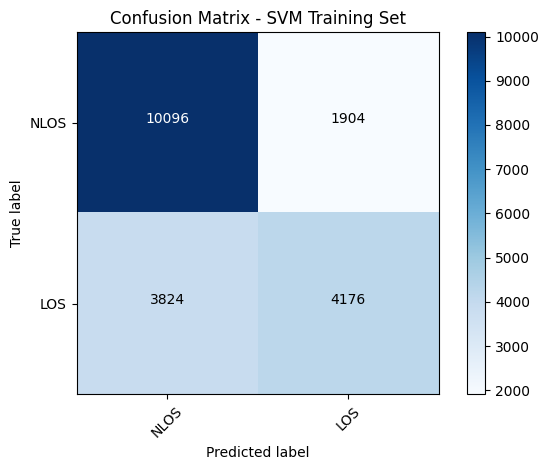

Confusion Matrix:
[[10096  1904]
 [ 3824  4176]]


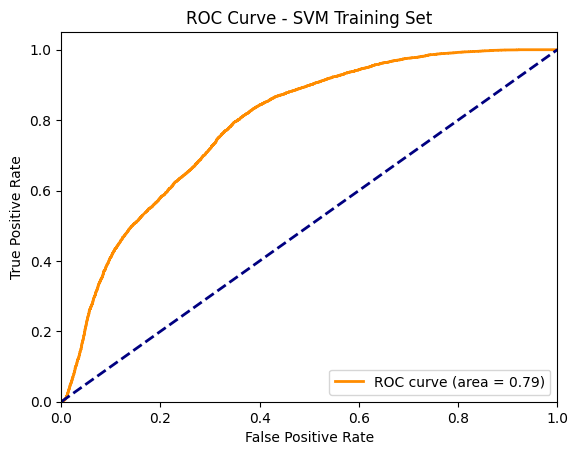

Metrics for SVM Training Set:
Accuracy: 0.7136
Precision: 0.6868
Recall (Sensitivity): 0.5220
Specificity: 0.8413
F1 Score: 0.5932
ROC AUC: 0.7886
Log Loss: 0.5553


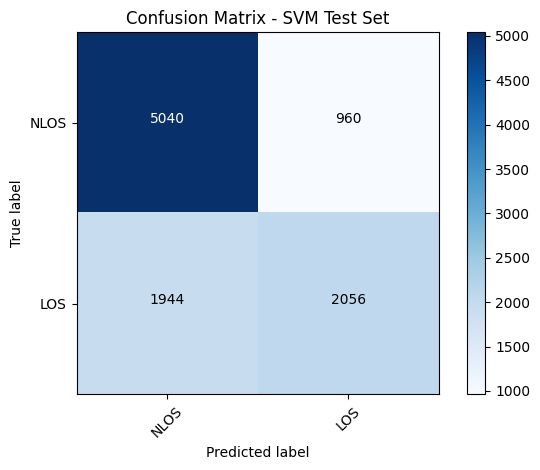

Confusion Matrix:
[[5040  960]
 [1944 2056]]


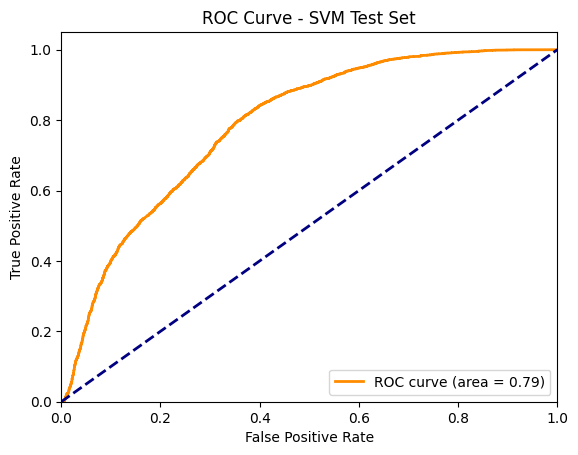

Metrics for SVM Test Set:
Accuracy: 0.7096
Precision: 0.6817
Recall (Sensitivity): 0.5140
Specificity: 0.8400
F1 Score: 0.5861
ROC AUC: 0.7860
Log Loss: 0.5594


In [25]:
print("\nTraining with SVM...")
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_svm(
    features, labels, features_test, labels_test, kernel='rbf', C=1.0
)
y_train_prob = y_train_prob[:, 1]  # Assuming binary classification, take the probability of the positive class
y_test_prob = y_test_prob[:, 1]  # Assuming binary classification, take the probability of the positive class
plot_confusion_matrix(y_train, y_train_pred, title='Confusion Matrix - SVM Training Set')
plot_roc_curve(y_train, y_train_prob, title='ROC Curve - SVM Training Set')
print("Metrics for SVM Training Set:")
print_metrics(y_train, y_train_pred, y_train_prob)

plot_confusion_matrix(y_test, y_test_pred, title='Confusion Matrix - SVM Test Set')
plot_roc_curve(y_test, y_test_prob, title='ROC Curve - SVM Test Set')
print("Metrics for SVM Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob)

In [ ]:
print("\nTraining with Random Forest...")
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_random_forest(
    features, labels, features_test, labels_test, n_estimators=100, max_depth=10, min_samples_split=5, min_samples_leaf=2
)
y_train_prob = y_train_prob[:, 1]  # Assuming binary classification, take the probability of the positive class
y_test_prob = y_test_prob[:, 1]
plot_confusion_matrix(y_train, y_train_pred, title='Confusion Matrix - Random Forest Training Set')
plot_roc_curve(y_train, y_train_prob, title='ROC Curve - Random Forest Training Set')
print("Metrics for Random Forest Training Set:")
print_metrics(y_train, y_train_pred, y_train_prob)

plot_confusion_matrix(y_test, y_test_pred, title='Confusion Matrix - Random Forest Test Set')
plot_roc_curve(y_test, y_test_prob, title='ROC Curve - Random Forest Test Set')
print("Metrics for Random Forest Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob)


Training with Random Forest...


TypeError: train_random_forest() got an unexpected keyword argument 'max_depth'

In [ ]:
print("\nTraining with XGBoost...")
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_xgboost(
    features, labels, features_test, labels_test, n_estimators=100, learning_rate=0.1, max_depth=5
)
plot_confusion_matrix(y_train, y_train_pred, title='Confusion Matrix - XGBoost Training Set')
plot_roc_curve(y_train, y_train_prob, title='ROC Curve - XGBoost Training Set')
print("Metrics for XGBoost Training Set:")
print_metrics(y_train, y_train_pred, y_train_prob)

plot_confusion_matrix(y_test, y_test_pred, title='Confusion Matrix - XGBoost Test Set')
plot_roc_curve(y_test, y_test_prob, title='ROC Curve - XGBoost Test Set')
print("Metrics for XGBoost Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob)